# Recursive 7-day forecasts with the Stage 3 model (CA_1 / FOODS)

The production model predicts **one day ahead**: every row uses yesterday's actual sales (`sales_lag_1`). The app would also like a 7-day view. Without training a new model, the only way to get one is **recursive forecasting**. Predict day 1, write that prediction into the history as if it had been observed, rebuild the features, predict day 2, and so on.

Errors can compound, and the model never saw its own predictions as inputs during training. So the design document (§10.5) keeps the 7-day horizon switched off until this experiment shows it is worthwhile.

**Setup**

- Model: `m5-ca1-foods@1.1.0-bt`, trained on `d_22`–`d_1913`, so every forecast below is out of sample.
- Forecast origins (as-of dates): every day from `d_1913` (2016-04-24) to `d_1934` (2016-05-15). That gives 22 origins × 1,437 items × 7 days, all inside the observed backtest window `d_1914`–`d_1941`.
- Recursion uses `mlengine.models.forecaster.Forecaster`, the same code the ML service runs.
- Baselines for the same 7 days: **naive** (the as-of day's sales repeated) and **seasonal naive** (the same weekday last week).

**Decision rule (set before running):** enable `H = 7` only if the recursive AI forecast beats *both* baselines on aggregate 7-day RMSE **and** MAE.

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# The notebooks live in notebooks/; mlengine lives in the project root.
projectRoot = Path.cwd().resolve()
while not (projectRoot / "mlengine").is_dir() and projectRoot != projectRoot.parent:
    projectRoot = projectRoot.parent
sys.path.insert(0, str(projectRoot))
figuresDir = projectRoot / "reports" / "figures"
tablesDir = projectRoot / "reports" / "tables"
figuresDir.mkdir(parents=True, exist_ok=True)
tablesDir.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

import mlengine
from mlengine import config
print(f"mlengine {mlengine.__version__} from {projectRoot}")

mlengine 0.1.0 from /home/karanei/SemProject_MLEngine


In [2]:
from mlengine.data.m5 import daily_price_matrix, load_m5_scope, scope_to_batch
from mlengine.models import baselines
from mlengine.models.artifact import ModelRegistry
from mlengine.models.forecaster import Forecaster

scope = load_m5_scope(verify_overlap=False)
dailyPrices = daily_price_matrix(scope)
registry = ModelRegistry()
backtestModel = registry.get("m5-ca1-foods", "1.1.0-bt")
forecaster = Forecaster(backtestModel)
print(f"Model: {backtestModel.ref}, trained up to {backtestModel.training_end_date}")
print(f"Series: {len(scope.identity):,}")

Model: m5-ca1-foods@1.1.0-bt, trained up to 2016-04-24
Series: 1,437


In [3]:
HORIZON = 7
originDays = np.arange(1913, 1941 - HORIZON + 1)  # last origin leaves 7 observed days to score

aiForecasts, naiveForecasts, seasonalForecasts, actuals = [], [], [], []
for originDay in originDays:
    batch = scope_to_batch(scope, int(originDay), history_days=365, horizon=HORIZON, daily_prices=dailyPrices)
    output = forecaster.forecast(batch, HORIZON)
    aiForecasts.append(output.ai)
    naiveForecasts.append(baselines.naive_last_value(batch.sales, HORIZON))
    seasonalForecasts.append(baselines.seasonal_naive_7(batch.sales, HORIZON))
    actuals.append(scope.sales[:, originDay : originDay + HORIZON])

aiForecasts, naiveForecasts = np.stack(aiForecasts), np.stack(naiveForecasts)
seasonalForecasts, actuals = np.stack(seasonalForecasts), np.stack(actuals)
print(f"Forecast array shape (origins, series, horizon days): {aiForecasts.shape}")
print(f"Unavailable AI forecasts: {int(np.isnan(aiForecasts).sum())}")

Forecast array shape (origins, series, horizon days): (22, 1437, 7)
Unavailable AI forecasts: 0


### Consistency check

Day 1 of each recursive forecast is an ordinary one-step forecast, so it must equal the stored one-step backtest predictions of the same model.

In [4]:
storedPredictions = pd.read_parquet(backtestModel.path / "backtest" / "predictions.parquet")
storedWide = storedPredictions.pivot(index="product_id", columns="date", values="ai")
dayOneDates = [str(config.m5_day_to_date(int(d) + 1)) for d in originDays]
storedDayOne = storedWide.loc[scope.identity["item_id"], dayOneDates].to_numpy().T
print(f"Max |difference| on day 1: {np.abs(storedDayOne - aiForecasts[:, :, 0]).max():.2e}")

Max |difference| on day 1: 3.70e-06


In [5]:
from mlengine.evaluation import metrics

methods = {"AI (recursive)": aiForecasts, "Naive (last value)": naiveForecasts, "Seasonal naive (t-7)": seasonalForecasts}
rows = []
for horizonDay in range(HORIZON):
    for name, values in methods.items():
        summary = metrics.summary(actuals[:, :, horizonDay], values[:, :, horizonDay])
        rows.append({"horizon_day": horizonDay + 1, "method": name, **summary})
byHorizon = pd.DataFrame(rows)
rmseTable = byHorizon.pivot(index="horizon_day", columns="method", values="rmse")
maeTable = byHorizon.pivot(index="horizon_day", columns="method", values="mae")
print("RMSE by horizon day")
display(rmseTable)
print("MAE by horizon day")
display(maeTable)
byHorizon.to_csv(tablesDir / "recursive_horizon_errors.csv", index=False)

RMSE by horizon day


method,AI (recursive),Naive (last value),Seasonal naive (t-7)
horizon_day,,,
1,2.337,3.194,3.115
2,2.396,3.507,3.132
3,2.469,3.698,3.170
4,2.482,3.738,3.168
5,2.504,3.614,3.178
6,2.529,3.376,3.207
7,2.580,3.257,3.257


MAE by horizon day


method,AI (recursive),Naive (last value),Seasonal naive (t-7)
horizon_day,,,
1,1.374,1.740,1.734
2,1.438,1.880,1.740
3,1.454,1.936,1.749
4,1.464,1.938,1.758
5,1.478,1.898,1.769
6,1.493,1.837,1.780
7,1.505,1.792,1.792


In [6]:
aggregate = pd.DataFrame([{"method": name, **metrics.summary(actuals, values)} for name, values in methods.items()])
aggregate = aggregate.set_index("method")
display(aggregate)

ai = aggregate.loc["AI (recursive)"]
beatsBoth = all(
    ai["rmse"] < aggregate.loc[b, "rmse"] and ai["mae"] < aggregate.loc[b, "mae"]
    for b in ["Naive (last value)", "Seasonal naive (t-7)"]
)
print(f"Decision rule met (beats both baselines on 7-day RMSE and MAE): {beatsBoth}")
for b in ["Naive (last value)", "Seasonal naive (t-7)"]:
    print(f"  vs {b}: RMSE {100 * (1 - ai['rmse'] / aggregate.loc[b, 'rmse']):.1f}% lower, "
          f"MAE {100 * (1 - ai['mae'] / aggregate.loc[b, 'mae']):.1f}% lower")

,n,mae,rmse,wape
method,,,,
AI (recursive),221298,1.458,2.472,0.639
Naive (last value),221298,1.860,3.489,0.815
Seasonal naive (t-7),221298,1.760,3.176,0.772


Decision rule met (beats both baselines on 7-day RMSE and MAE): True
  vs Naive (last value): RMSE 29.1% lower, MAE 21.6% lower
  vs Seasonal naive (t-7): RMSE 22.1% lower, MAE 17.2% lower


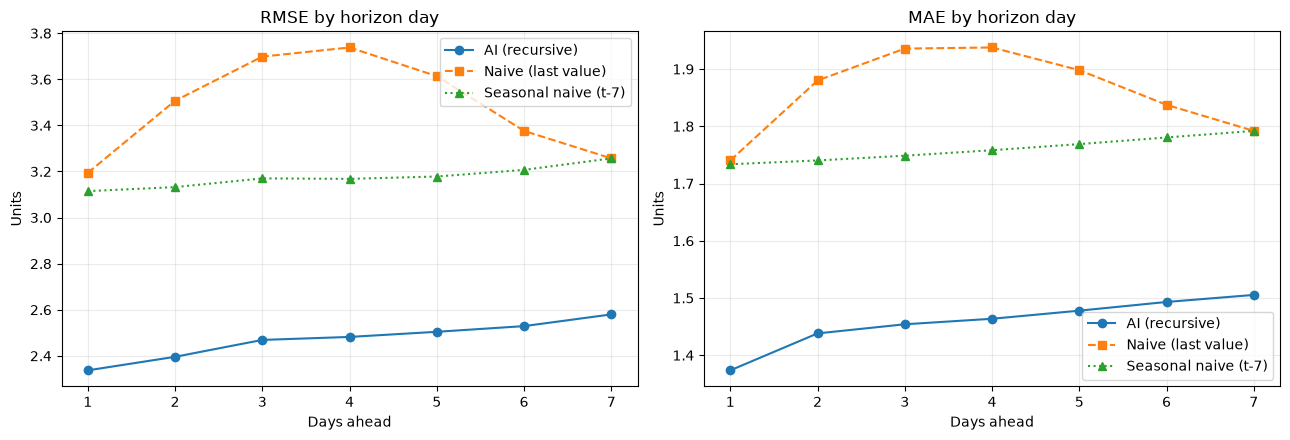

In [7]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
styles = {"AI (recursive)": "-o", "Naive (last value)": "--s", "Seasonal naive (t-7)": ":^"}
for name in methods:
    axes[0].plot(rmseTable.index, rmseTable[name], styles[name], label=name)
    axes[1].plot(maeTable.index, maeTable[name], styles[name], label=name)
axes[0].set_title("RMSE by horizon day")
axes[1].set_title("MAE by horizon day")
for axis in axes:
    axis.set_xlabel("Days ahead")
    axis.set_ylabel("Units")
    axis.legend()
figure.tight_layout()
figure.savefig(figuresDir / "recursive_horizon_errors.png", dpi=120, bbox_inches="tight")
plt.show()

### Does recursion drift? Forecast level versus actual level

If feeding predictions back in made forecasts drift up or down, the mean forecast would move away from the mean actual as the horizon grows.

In [8]:
levels = pd.DataFrame({
    "mean_actual": actuals.mean(axis=(0, 1)),
    "mean_ai_forecast": aiForecasts.mean(axis=(0, 1)),
    "mean_naive_forecast": naiveForecasts.mean(axis=(0, 1)),
}, index=pd.RangeIndex(1, HORIZON + 1, name="horizon_day"))
levels["ai_bias"] = levels["mean_ai_forecast"] - levels["mean_actual"]
display(levels)

,mean_actual,mean_ai_forecast,mean_naive_forecast,ai_bias
horizon_day,,,,
1,2.254,2.243,2.281,-0.011
2,2.251,2.343,2.281,0.092
3,2.261,2.349,2.281,0.088
4,2.273,2.353,2.281,0.080
5,2.290,2.376,2.281,0.086
6,2.314,2.403,2.281,0.090
7,2.326,2.406,2.281,0.081


## Conclusions

**The recursive 7-day forecast meets the decision rule, so `H = 7` is enabled** in `m5-ca1-foods` (from model version 1.1.0 onward; see `mlengine/pipelines/m5_release.py`).

| 7-day aggregate (22 origins × 1,437 items × 7 days) | RMSE | MAE | WAPE |
| --- | --- | --- | --- |
| **AI, recursive** | **2.472** | **1.458** | **63.9%** |
| Seasonal naive (t−7) | 3.176 | 1.760 | 77.2% |
| Naive (last value) | 3.489 | 1.860 | 81.5% |

- **The AI lead holds across the whole week.** Recursive AI RMSE rises from 2.34 on day 1 to 2.58 on day 7, about 10% worse. That is a gentle degradation, and on every single horizon day it stays well below both baselines (22–29% lower RMSE overall).
- **Naive persistence degrades much faster** (3.19 → 3.74 by day 4). Its error dips again at day 7 because the as-of day and day 7 fall on the same weekday, which is the weekly pattern the seasonal baseline exploits.
- **Recursion adds a small upward bias.** From day 2 the mean AI forecast runs about 0.08–0.09 units above the mean actual (about 4%). This is the price of feeding expected values back in as if they were observations. It is small, but the model card should mention it, and a direct multi-horizon model would avoid it.
- **Day 1 matches the stored one-step backtest** (max difference 3.7e-06), which confirms the serving path and the training path agree.
- Caveat: one store, one dense category, and a 4-week window. The per-day error curve is published on the model card so the app can show how accuracy falls off with distance.
